In [1]:
import pickle
import matplotlib.pyplot as plt
import numpy as np
from glob import glob
from os import path
import seaborn as sns
import pandas as pd
import warnings

# set seaborn style
sns.set_theme(style="ticks", context="talk")
mars_radius = 3390

# filter FutureWarning
warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:

data = """
1.0008130081300812, 150
0.9595528455284552, 151.19565217391303
0.9359756097560976, 152.73291925465838
0.9182926829268292, 154.44099378881987
0.9182926829268292, 156.49068322981367
0.9477642276422764, 158.3695652173913
1.0008130081300812, 159.0527950310559
1.0479674796747966, 159.90683229813664
1.0833333333333333, 161.1024844720497
1.0833333333333333, 161.1024844720497
1.1010162601626017, 161.95652173913044
1.106910569105691, 163.15217391304347
1.1186991869918699, 164.17701863354037
1.0951219512195123, 165.54347826086956
1.0951219512195123, 165.54347826086956
1.136382113821138, 168.1055900621118
1.136382113821138, 168.1055900621118
1.159959349593496, 169.30124223602485
1.1658536585365855, 171.1801242236025
1.1304878048780487, 171.86335403726707
1.0951219512195123, 172.37577639751552
1.1245934959349593, 173.22981366459626
1.1776422764227643, 173.74223602484471
1.1953252032520325, 174.42546583850933
1.2130081300813007, 174.93788819875778
1.2130081300813007, 174.93788819875778
1.2660569105691057, 176.4751552795031
1.2660569105691057, 176.4751552795031
1.3132113821138212, 176.8167701863354
1.366260162601626, 178.01242236024845
1.4075203252032522, 179.37888198757764
1.4252032520325204, 180.91614906832297
1.4134146341463416, 182.11180124223603
1.3957317073170732, 183.47826086956522
1.3839430894308942, 185.01552795031057
1.3957317073170732, 187.2360248447205
1.4075203252032522, 188.09006211180125
1.4075203252032522, 188.09006211180125
1.4428861788617886, 188.77329192546583
1.4782520325203252, 190.13975155279502
1.5077235772357724, 190.82298136645963
1.5430894308943088, 191.33540372670808
1.584349593495935, 192.70186335403727
1.5961382113821139, 193.38509316770185
1.5961382113821139, 193.38509316770185
1.5902439024390245, 194.9223602484472
1.6315040650406503, 196.80124223602485
1.6550813008130083, 198.50931677018633
1.7022357723577235, 199.87577639751552
1.8083333333333336, 200.90062111801242
1.8083333333333336, 200.90062111801242
1.7729674796747967, 200.72981366459626
1.8083333333333336, 202.9503105590062
1.8495934959349594, 203.9751552795031
1.896747967479675, 205.17080745341616
1.9497967479674796, 206.70807453416148
1.9674796747967482, 207.73291925465838
1.9733739837398376, 211.14906832298135
2.0441056910569104, 212.3447204968944
2.1089430894308943, 215.24844720496895
2.1678861788617887, 216.78571428571428
2.203252032520325, 217.81055900621118
2.226829268292683, 219.51863354037266
2.226829268292683, 220.88509316770185
2.2916666666666665, 222.0807453416149
2.338821138211382, 223.1055900621118
2.4272357723577236, 226.00931677018633
2.5215447154471544, 228.22981366459626
2.5215447154471544, 228.22981366459626
2.4920731707317074, 227.54658385093165
2.391869918699187, 224.81366459627327
2.5569105691056913, 229.4254658385093
2.5922764227642277, 230.79192546583852
2.6453252032520327, 232.15838509316768
2.733739837398374, 233.69565217391303
2.798577235772358, 235.40372670807454
2.8869918699186994, 237.96583850931677
2.98130081300813, 240.8695652173913
3.099186991869919, 244.45652173913044
3.211178861788618, 248.04347826086956
3.276016260162602, 250.77639751552795
3.3113821138211383, 252.82608695652175
3.452845528455285, 255.9006211180124
3.5825203252032525, 258.9751552795031
3.700406504065041, 261.0248447204969
3.835975609756098, 263.5869565217391
3.965650406504065, 265.9782608695652
4.12479674796748, 268.5403726708074
4.3134146341463415, 271.6149068322981
4.460772357723577, 274.17701863354034
4.584552845528456, 276.7391304347826
4.696544715447154, 279.81366459627327
4.808536585365854, 282.5465838509317
4.920528455284552, 284.7670807453416
5.056097560975609, 287.67080745341616
5.173983739837398, 290.2329192546584
5.291869918699187, 292.4534161490683
5.462804878048781, 295.3571428571429
5.627845528455285, 298.43167701863354
5.828252032520325, 301.1645962732919
5.952032520325203, 303.72670807453414
6.140650406504065, 306.97204968944095
"""

# Split the data into lines, then split each line on the comma and convert to float
data_array = np.array([list(map(float, line.split(','))) for line in data.strip().split('\n')])
tian_grow = data_array[:, 0]
tian_altitudes = data_array[:, 1]

In [3]:
data = """4.994565217391305, 313.91616766467064
4.899456521739131, 312.23952095808386
4.759963768115942, 309.38922155688624
4.607789855072464, 306.3712574850299
4.385869565217392, 302.17964071856284
4.0815217391304355, 296.47904191616766
3.916666666666667, 293.4610778443114
3.5552536231884058, 284.07185628742513
3.3967391304347827, 274.01197604790417
2.921195652173913, 263.9520958083832
2.33786231884058, 244
2.261775362318841, 234.4431137724551
1.9891304347826089, 223.88023952095807
1.7798913043478262, 213.31736526946108
1.5769927536231885, 200.5748502994012
1.4248188405797102, 189.34131736526945
1.3677536231884058, 184.1437125748503
1.2092391304347827, 175.4251497005988
1.190217391304348, 171.73652694610777
1.1331521739130435, 163.8562874251497
1.0570652173913044, 158.99401197604791
1, 150.61077844311376
"""

# Split the data into lines, then split each line on the comma and convert to float
data_array = np.array([list(map(float, line.split(','))) for line in data.strip().split('\n')])
spherical_1d_grow = data_array[:, 0]
spherical_1d_altitudes = data_array[:, 1]

In [4]:
# Define column names
column_names = ["cell_num", "i_rad", "i_zen", "i_azi", "rad_lower", "rad_upper", "zen_lower", "zen_upper", "azi_lower", "azi_upper", "rad_width", "zen_width", "azi_width", "volume"]

results_path = '/mnt/i/ArchiveSims/Results_20240711_195318.099'

# Read the file
df = pd.read_csv(f"{results_path}/Info/Grid.ascii", delim_whitespace=True, header=None, names=column_names)
df['volume'][0] * 1e-9

290637.4965531645

In [5]:
# read back the parquet file
df = pd.read_parquet('/mnt/i/ArchiveSims/growth_peak_data.parquet')

df['Azi Num'] = df['Azi'].str.strip('azi').astype(int)

df.head()

,Amp,Azi,Azi Cells,Radial Distance,Density Amplitude Growth,Density Amplitude,Cell Size,"Amp, Cell Size",Heat Lapse,Azi Num
0,0.083333,33azi,72,148.318222,1.000000,0.041824,6,"0.0833333333, 6",0.257098,33
1,0.083333,33azi,72,153.506927,1.142341,0.047777,6,"0.0833333333, 6",0.257098,33
2,0.083333,33azi,72,159.397140,1.262983,0.052822,6,"0.0833333333, 6",0.257098,33
3,0.083333,33azi,72,166.197209,1.257371,0.052588,6,"0.0833333333, 6",0.257098,33
4,0.083333,33azi,72,174.220912,1.435582,0.060041,6,"0.0833333333, 6",0.257098,33


In [6]:
d_azi = 360 / df['Azi Cells']
d_zen = 2 * 360 / df['Azi Cells']
zen1 = 90 - d_zen / 2
zen2 = 90 + d_zen / 2



(cell_rad_upper_bounds(i_rad) * cell_rad_upper_bounds(i_rad) * cell_rad_upper_bounds(i_rad) - cell_rad_lower_bounds(i_rad) * cell_rad_lower_bounds(i_rad) * cell_rad_lower_bounds(i_rad)) * (-COS(cell_zen_upper_bounds(i_zen)) + COS(cell_zen_lower_bounds(i_zen))) * (cell_azi_upper_bounds(i_azi) - cell_azi_lower_bounds(i_azi)) / 3.d0

SyntaxError: invalid decimal literal (3759769925.py, line 8)

In [7]:
unique_heat_lapses = df[['Heat Lapse', 'Amp', 'Azi', 'Azi Num', 'Cell Size', 'Azi Cells']].drop_duplicates()

azi_length_cell_deg = 360 / unique_heat_lapses['Azi Cells']
azi_length_cell_rad = np.deg2rad(azi_length_cell_deg)
azi_length_cell_km = (mars_radius + 100) * azi_length_cell_rad
azi_length_cell_m = azi_length_cell_km * 1000   # cell size horizontally in km
unique_heat_lapses['Length'] = azi_length_cell_km

# sort by Azi Num
unique_heat_lapses = unique_heat_lapses.sort_values('Azi Num')

# Apply cumsum for each group of Amp, Cell Size
unique_heat_lapses['Cum Length'] = unique_heat_lapses.groupby(['Amp', 'Cell Size'])['Length'].transform('cumsum')
unique_heat_lapses

# Subtract the cumsum from the total length to get the start of each cell
unique_heat_lapses['Start'] = unique_heat_lapses['Cum Length'] - unique_heat_lapses['Length']

# Add half a cell to the start to get the center of the cell
unique_heat_lapses['Center'] = unique_heat_lapses['Start'] + unique_heat_lapses['Length'] / 2  # center position of each cell horziontally

# Assign total length to each row
unique_heat_lapses['Total Length'] = unique_heat_lapses.groupby(['Amp', 'Cell Size', 'Azi Cells'])['Length'].transform('sum')

In [8]:
# Filter out rows whose Azi Cells is equal to 72
df_subset72_cells = df[df['Azi Cells'] == 72]

# sort by Cell Size
df_subset72_cells = df_subset72_cells.sort_values(by='Cell Size')

# and drop the Azi Cells column
# df_subset72_cells = df_subset72_cells.drop(columns=['Azi Cells'])

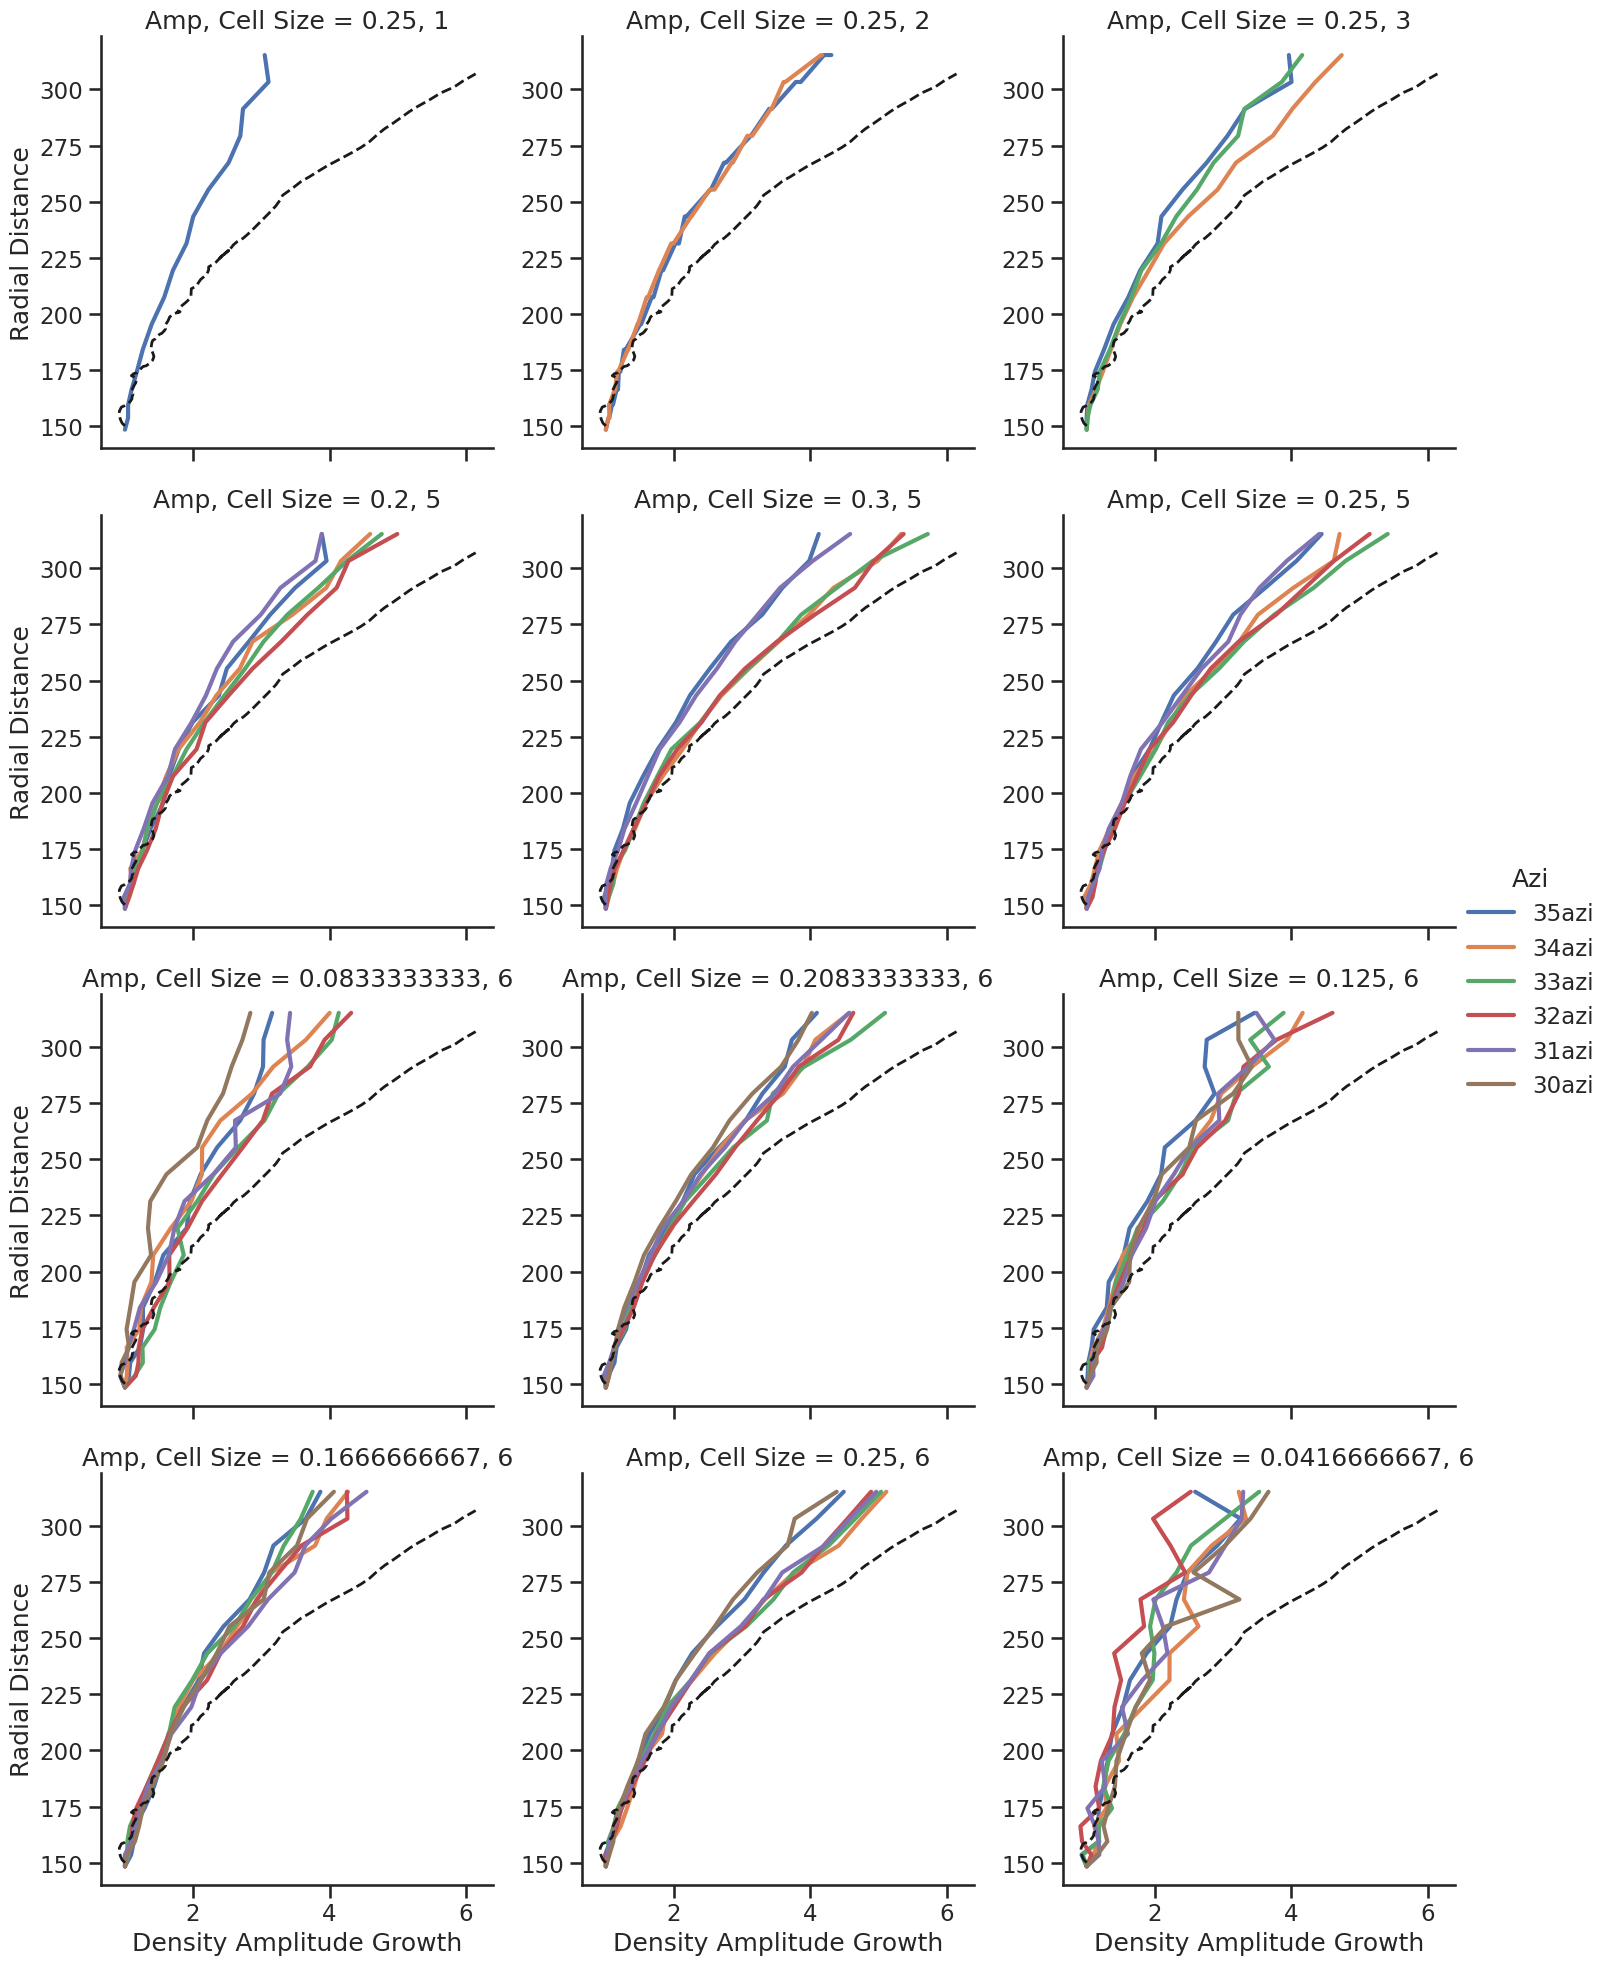

In [9]:
# now use sns.FacetGrid to plot the data
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)
    g = sns.FacetGrid(df_subset72_cells, col='Amp, Cell Size', hue='Azi', sharey=False, height=5, col_wrap=3)
    g.map_dataframe(sns.lineplot, 'Density Amplitude Growth', 'Radial Distance', orient='y', lw=3, style='Cell Size', dashes=True, estimator=None)
    # line plot tian_grow as well for every subplot
    for ax in g.axes.flat:
        ax.plot(tian_grow, tian_altitudes, label = 'Tian et al., 2023', lw=2, color='k', ls='--')
g.add_legend()

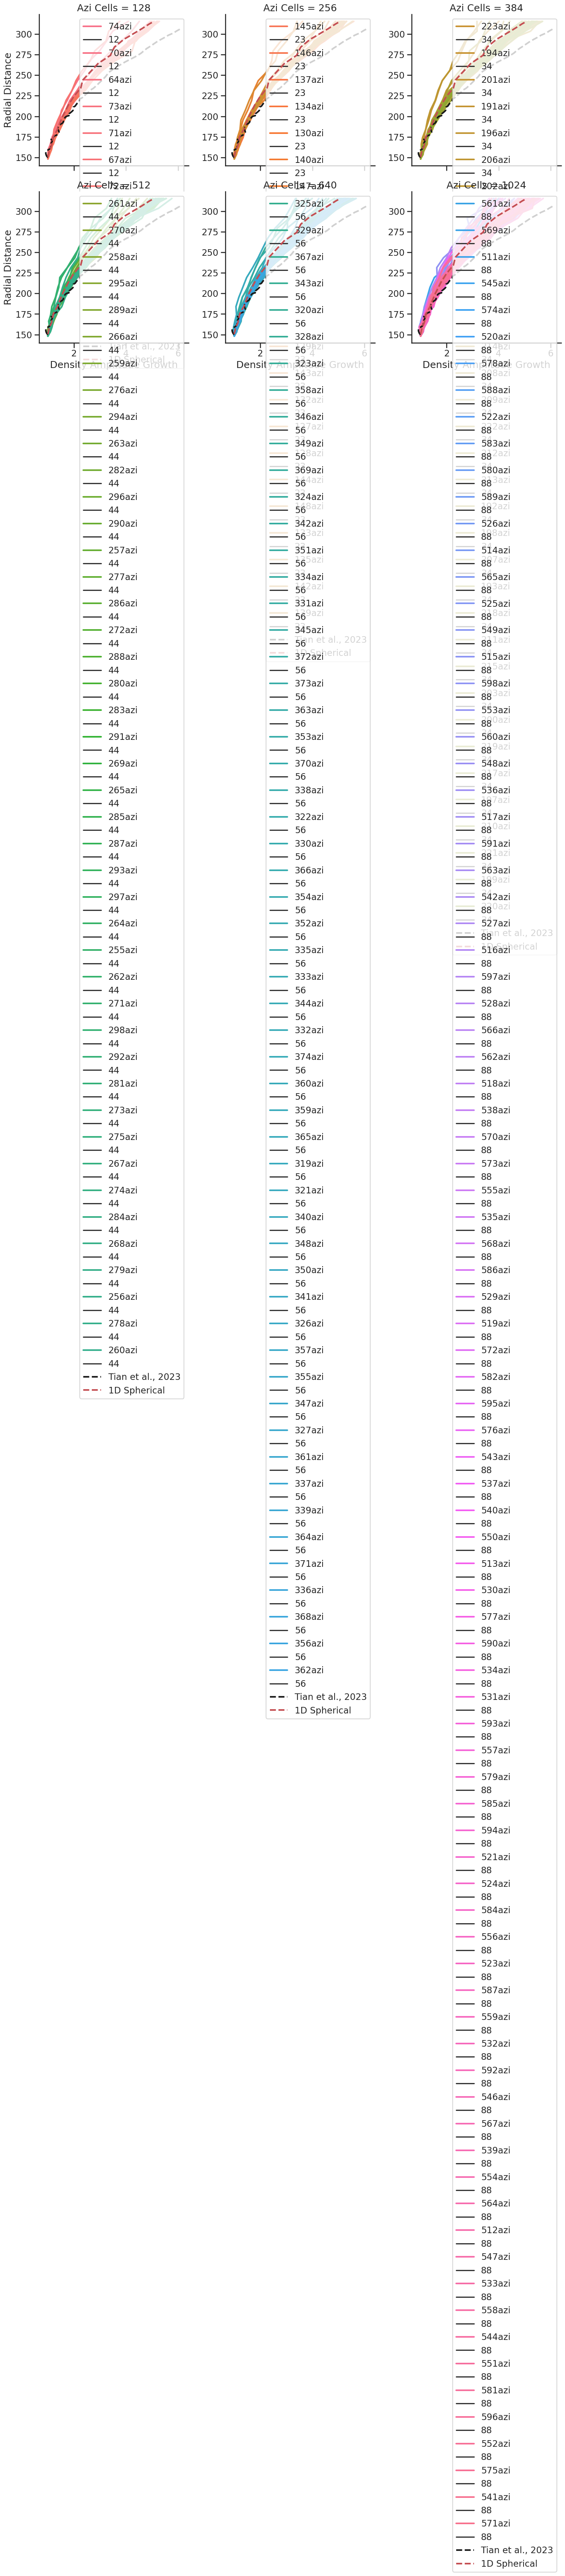

In [20]:
# Filter out rows whose Azi Cells are not equal to 72
df_subset_neq72_cells = df[df['Azi Cells'] != 72]

# sort by Cell Size
df_subset_neq72_cells = df_subset_neq72_cells.sort_values(by='Cell Size')

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)
    g = sns.FacetGrid(df_subset_neq72_cells, col='Azi Cells', hue='Azi', sharey=False, height=5, col_wrap=3)
    g.map_dataframe(sns.lineplot, 'Density Amplitude Growth', 'Radial Distance', orient='y', lw=3, style='Cell Size', dashes=True, estimator=None)
    # line plot tian_grow as well for every subplot
    for ax in g.axes.flat:
        ax.plot(tian_grow, tian_altitudes, label = 'Tian et al., 2023', lw=3, color='k', ls='--')
        ax.plot(spherical_1d_grow, spherical_1d_altitudes, lw=3, color='r', ls='--', zorder=10, label='1D Spherical')
        # add the legend onhly to the first subplot
        ax.legend()
# g.add_legend()


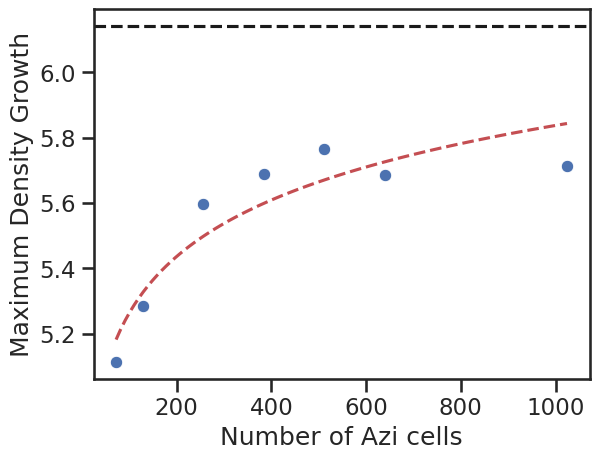

In [8]:
df_filtered = df[(df['Cell Size'] >= 6) & (df['Amp'] == 0.25)]
df_filtered_grouped = df_filtered.groupby('Azi Cells').agg({'Density Amplitude Growth': 'max'}).reset_index()
ax = sns.scatterplot(data=df_filtered_grouped, x='Azi Cells', y='Density Amplitude Growth')
ax.set(xlabel='Number of Azi cells', ylabel='Maximum Density Growth')

# fit a logaritmic curve to the data
from scipy.optimize import curve_fit
def func(x, a, b):
    return a * np.log(b * x)
popt, pcov = curve_fit(func, df_filtered_grouped['Azi Cells'], df_filtered_grouped['Density Amplitude Growth'])
x = np.linspace(df_filtered_grouped['Azi Cells'].min(), df_filtered_grouped['Azi Cells'].max(), 100)
y = func(x, *popt)
plt.plot(x, y, label=f'fit: a={popt[0]:.2f}, b={popt[1]:.2f}', color='r', ls='--')

# draw horizontal line at 6.140650406504065
plt.axhline(y=6.140650406504065, color='k', ls='--', label='Tian et al., 2023')

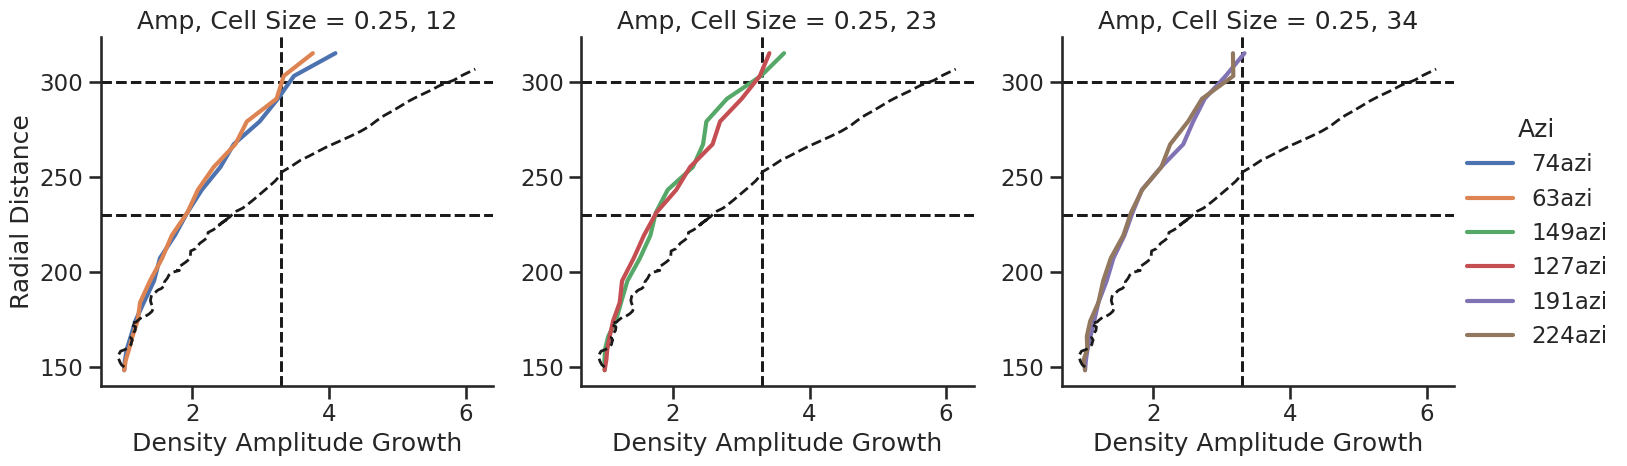

In [9]:
# from df_subset_neq72_cells, drop rows where Azi is not equal any of these: [191, 224, 127, 149, 63, 74]
df_subset_neq72_cells_edges = df_subset_neq72_cells[df_subset_neq72_cells['Azi Num'].isin([191, 224, 127, 149, 63, 74])]
df_subset_neq72_cells_center = df_subset_neq72_cells[df_subset_neq72_cells['Azi Num'].isin([68, 138, 207])]

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)
    g = sns.FacetGrid(df_subset_neq72_cells_edges, col='Amp, Cell Size', hue='Azi', sharey=False, height=5, col_wrap=3)
    g.map(plt.axhline, y=230, ls='--', color='k', lw=2)
    g.map(plt.axhline, y=300, ls='--', color='k', lw=2)
    
    # draw vertical line at 2.5
    g.map(plt.axvline, x=3.3, ls='--', color='k', lw=2)

    g.map_dataframe(sns.lineplot, 'Density Amplitude Growth', 'Radial Distance', orient='y', lw=3, style='Cell Size', dashes=True, estimator=None)
    # line plot tian_grow as well for every subplot
    for ax in g.axes.flat:
        ax.plot(tian_grow, tian_altitudes, label = 'Tian et al., 2023', lw=2, color='k', ls='--')


g.add_legend()

In [10]:
# unique_heat_lapses = df[['Heat Lapse', 'Amp', 'Azi', 'Cell Size', 'Azi Cells']].drop_duplicates()

# now groupby Cell Size and Azi and plot the summed Heat Lapse as a function of Amp
df_grouped = unique_heat_lapses.groupby(['Cell Size', 'Amp', 'Azi Cells']).agg({'Heat Lapse': 'sum'}).reset_index()
df_grouped

,Cell Size,Amp,Azi Cells,Heat Lapse
0,1,0.250000,72,1.746873
1,2,0.250000,72,10.924625
2,3,0.250000,72,7.812963
3,5,0.200000,72,12.265755
4,5,0.250000,72,18.681329
5,5,0.300000,72,24.727708
6,6,0.041667,72,0.999345
7,6,0.083333,72,2.738968
8,6,0.125000,72,5.731615
9,6,0.166667,72,10.481690


In [11]:
mars_radius = 3390
azi_length_cell_deg = 360 / df_grouped['Azi Cells']
azi_length_cell_rad = np.deg2rad(azi_length_cell_deg)
azi_length_cell_km = (mars_radius + 100) * azi_length_cell_rad
azi_length_cell_m = azi_length_cell_km * 1000
wave_arc_length_rad = azi_length_cell_rad * df_grouped['Cell Size']
wave_arc_length_km = (mars_radius + 100) * wave_arc_length_rad
wave_arc_length_m = wave_arc_length_km * 1000



In [12]:

df_grouped['Wave Arc Length'] = azi_length_cell_m
df_grouped['Norm HL'] = df_grouped['Heat Lapse'] / df_grouped['Wave Arc Length'] # the width of a cell m

df_grouped

# the sum of all heat lapses for each of the pertubed cells
# over the cell width of a cell

,Cell Size,Amp,Azi Cells,Heat Lapse,Wave Arc Length,Norm HL
0,1,0.250000,72,1.746873,304559.954473,0.000006
1,2,0.250000,72,10.924625,304559.954473,0.000036
2,3,0.250000,72,7.812963,304559.954473,0.000026
3,5,0.200000,72,12.265755,304559.954473,0.000040
4,5,0.250000,72,18.681329,304559.954473,0.000061
5,5,0.300000,72,24.727708,304559.954473,0.000081
6,6,0.041667,72,0.999345,304559.954473,0.000003
7,6,0.083333,72,2.738968,304559.954473,0.000009
8,6,0.125000,72,5.731615,304559.954473,0.000019
9,6,0.166667,72,10.481690,304559.954473,0.000034


In [13]:
from scipy.optimize import curve_fit

# Assuming df_subset_neq72_cells is your DataFrame

# Define the parabolic function
def parabola(x, a, b, c):
    return a * x**2 + b * x + c

def plot_fitted_parabola(x, y, **kwargs):
    # ensure data is longer than 3
    if len(x) <= 3:
        return
    # Fit the parabolic function to the data
    params, _ = curve_fit(parabola, x, y)
    # Generate a sequence of x values
    x_fit = np.linspace(x.min(), x.max(), 100)
    # Calculate the y values based on the fitted parameters
    y_fit = parabola(x_fit, *params)
    # Plot the fitted parabola
    plt.plot(x_fit, y_fit, color=kwargs.pop('color', 'red'), lw=kwargs.pop('lw', 2), ls=kwargs.pop('ls', '--'))

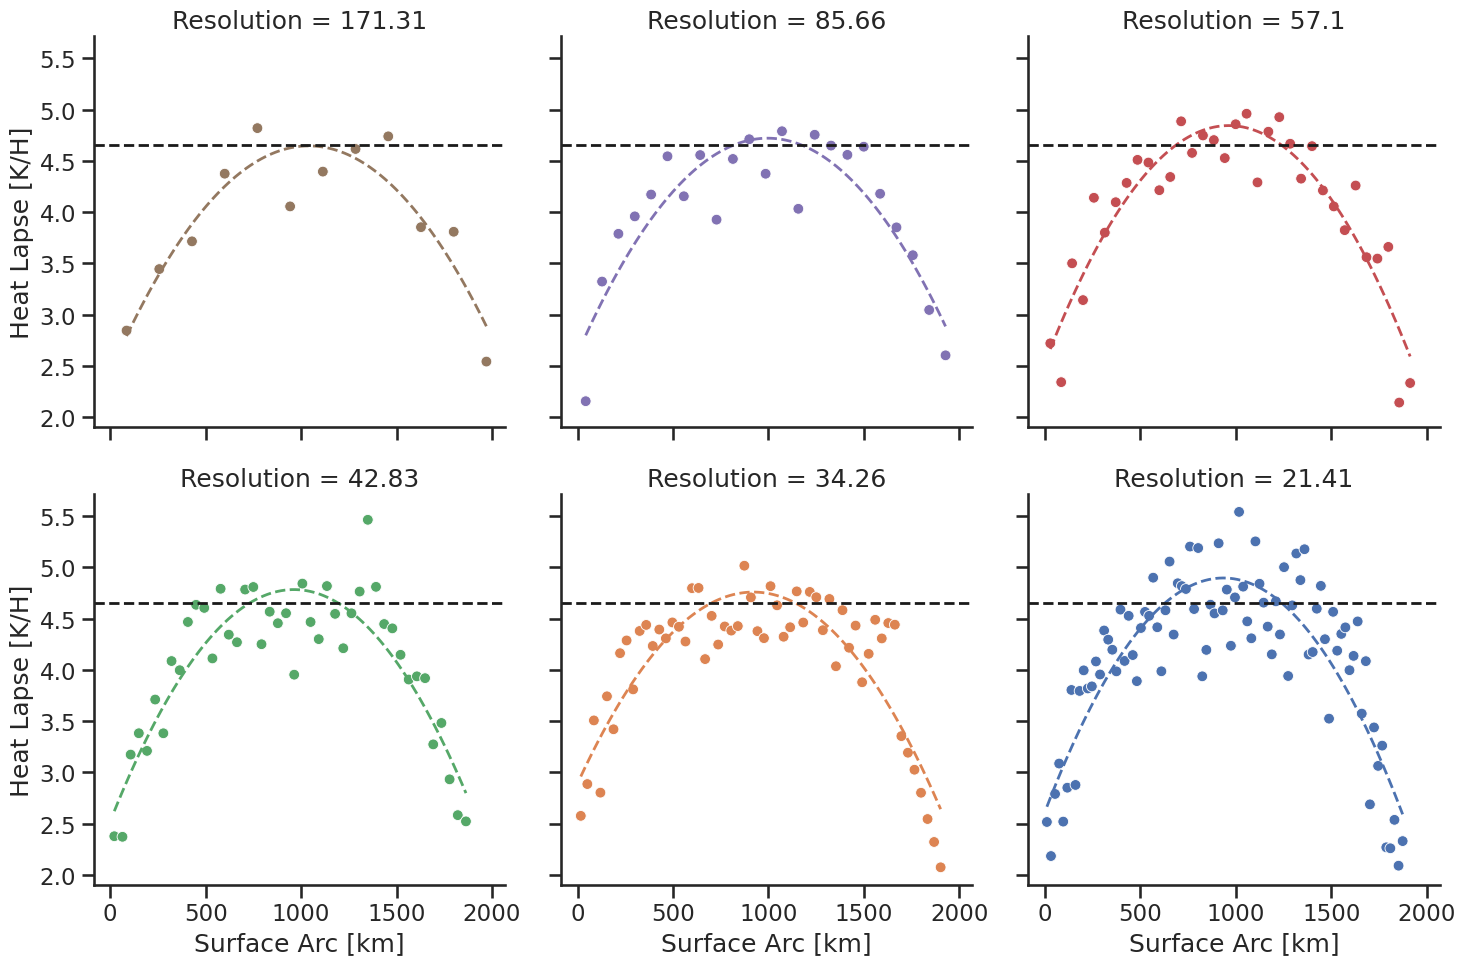

In [51]:
# unique_heat_lapses_subset = unique_heat_lapses[unique_heat_lapses['Azi Cells'] != 72]
# unique_heat_lapses_subset = unique_heat_lapses[(unique_heat_lapses['Amp'] == 0.25) & (unique_heat_lapses['Cell Size'] >= 6)]
unique_heat_lapses_subset = unique_heat_lapses[unique_heat_lapses['Cell Size'] > 6].copy()

# Round the Length valus to 2 decimals
unique_heat_lapses_subset['Resolution'] = unique_heat_lapses_subset['Length'].round(2)

# assing order of columns by length from longest to shortest
col_order = sorted(unique_heat_lapses_subset['Resolution'].unique())[::-1]

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)
    g = sns.FacetGrid(unique_heat_lapses_subset, col='Resolution', height=5, hue='Resolution', col_wrap=3, col_order=col_order)
    g.map_dataframe(sns.scatterplot, 'Center', 'Heat Lapse', 
                    lw=3, style='Cell Size', s=60)

    # Map the plotting function to the dataframe
    g.map(plot_fitted_parabola, 'Center', 'Heat Lapse')

    g.set_xlabels('Surface Arc [km]')
    g.set_ylabels('Heat Lapse [K/H]')

    # draw horizontal line at 4.65
    g.map(plt.axhline, y=4.65, ls='--', color='k', lw=2)

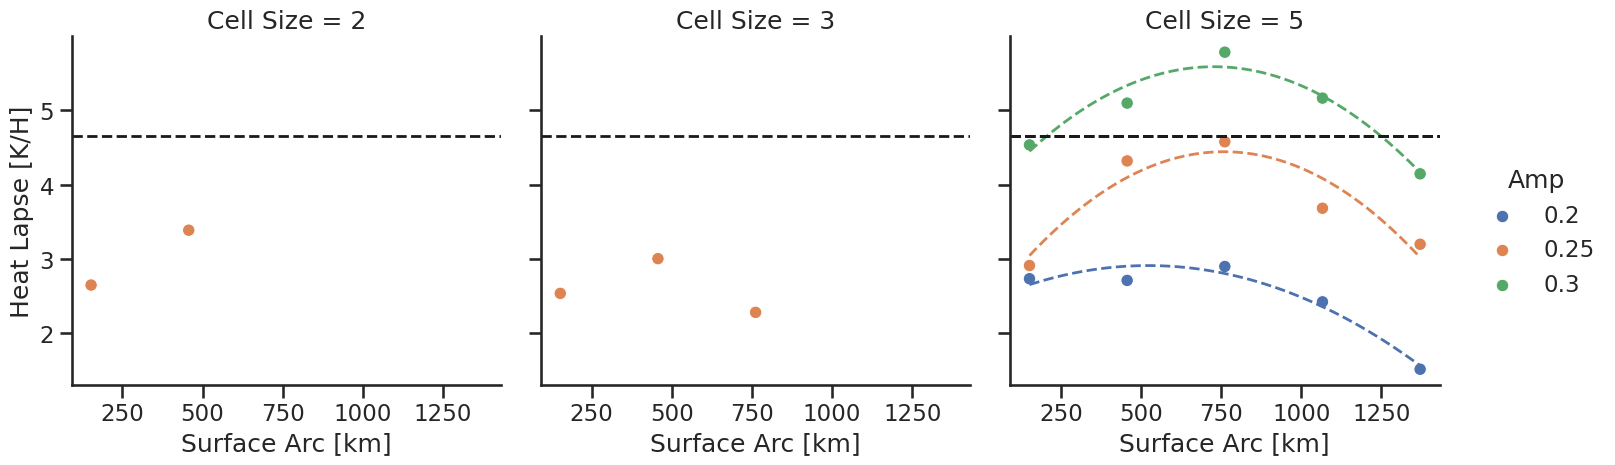

In [16]:
# unique_heat_lapses_subset = unique_heat_lapses[unique_heat_lapses['Azi Cells'] != 72]
# unique_heat_lapses_subset = unique_heat_lapses[(unique_heat_lapses['Amp'] == 0.25) & (unique_heat_lapses['Cell Size'] >= 6)]
unique_heat_lapses_subset = unique_heat_lapses[unique_heat_lapses['Cell Size'] < 6]

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)
    g = sns.FacetGrid(unique_heat_lapses_subset, col='Cell Size', height=5, hue='Amp')
    g.map_dataframe(sns.scatterplot, 'Center', 'Heat Lapse', 
                    lw=3, style='Cell Size')
    g.add_legend()
    # Map the plotting function to the dataframe
    g.map(plot_fitted_parabola, 'Center', 'Heat Lapse')

    g.set_xlabels('Surface Arc [km]')
    g.set_ylabels('Heat Lapse [K/H]')

    # draw horizontal line at 4.65
    g.map(plt.axhline, y=4.65, ls='--', color='k', lw=2)



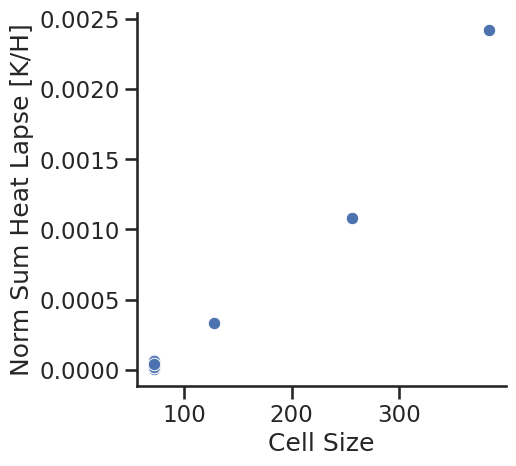

In [37]:
# df_grouped['Norm HL'] = df_grouped['Heat Lapse'] / df_grouped['Cell Size']
df_grouped = df_grouped.sort_values('Amp')

# susbet only Amp == 0.25
df_grouped = df_grouped[df_grouped['Amp'] == 0.25]

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)
    g = sns.relplot(
        data=df_grouped, x='Azi Cells', y='Norm HL', 
        height=5, aspect=1.1, lw=3,
    )
    g.set_ylabels('Norm Sum Heat Lapse [K/H]')
    # g.set_xlabels('Density Amplitude')
    g.set_xlabels('Cell Size')

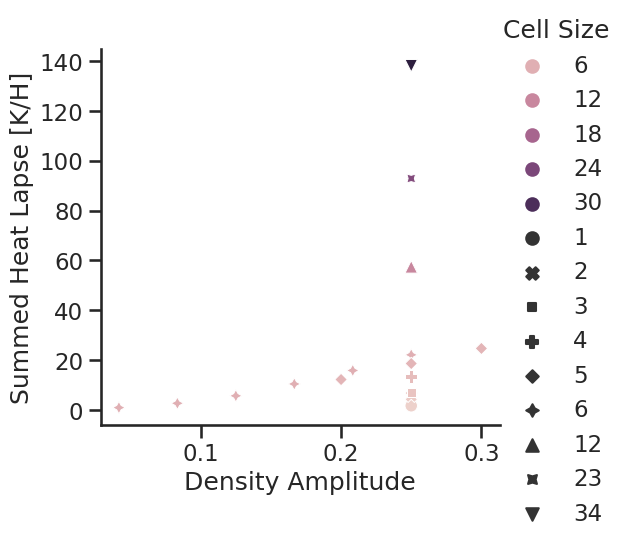

In [38]:
# unique_heat_lapses = df[['Heat Lapse', 'Amp', 'Azi', 'Cell Size']].drop_duplicates()

# now groupby Cell Size and Azi and plot the summed Heat Lapse as a function of Amp
df_grouped = unique_heat_lapses.groupby(['Cell Size', 'Amp']).agg({'Heat Lapse': 'sum'}).reset_index()

# sort by Amp
df_grouped = df_grouped.sort_values('Amp')

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)
    g = sns.relplot(
        data=df_grouped, x='Amp', y='Heat Lapse', hue='Cell Size', style='Cell Size',
        height=5, aspect=1.1, lw=3,
    )
    g.set_ylabels('Summed Heat Lapse [K/H]')
    g.set_xlabels('Density Amplitude')

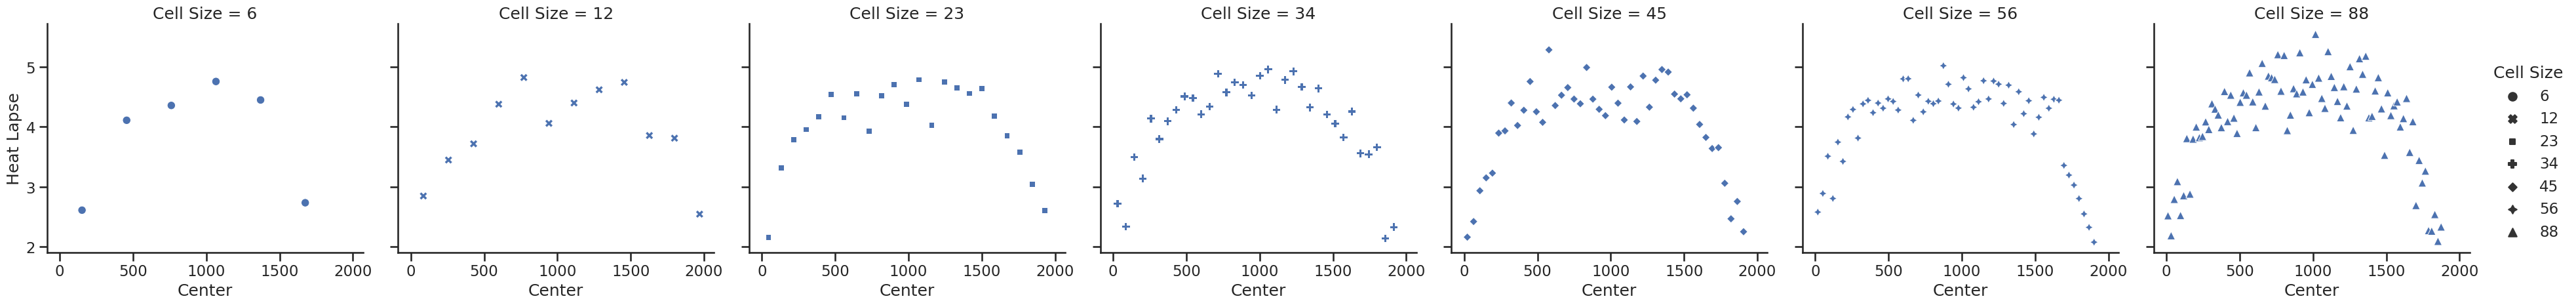

In [55]:
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)

    # filter out Amp != 0.25 AND only show Azi == 33-35azi
    # df_025 = df[(df['Amp'].isin(['0.25', '0.0417'])) & (df['Azi'].isin(['32azi', '33azi', '34azi', '35azi']))]

    g = sns.relplot(
        data=unique_heat_lapses[(unique_heat_lapses['Cell Size'] >= 6) & (unique_heat_lapses['Amp'] == 0.25)], x='Center', y='Heat Lapse', hue='Azi Cells', style='Cell Size', col="Cell Size",
        height=5, aspect=1.1, lw=3,
    )


0.0008078719744856636 4.675084107005255


,Cell Size,Azi Cells,Heat Lapse,Cum Length
0,6,72,4.753639,1827.359727
1,12,128,4.819515,2055.779693
2,23,256,4.789066,1970.122205
3,34,384,4.960116,1941.569710
4,45,512,5.281315,1927.293462
5,56,640,5.016707,1918.727713
6,88,1024,5.541773,1884.464718


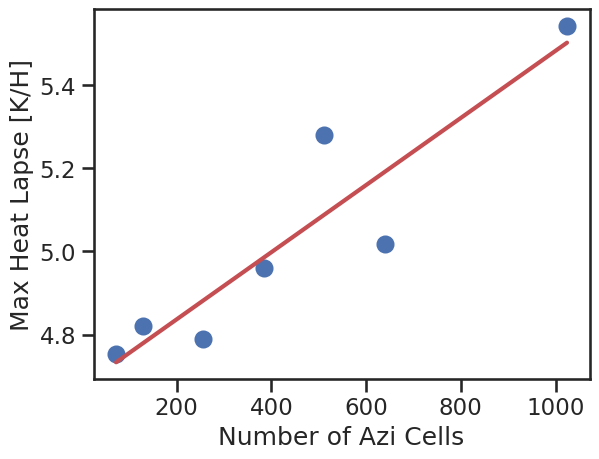

In [34]:
# for unique_heat_lapses[(unique_heat_lapses['Azi Cells'] < 100) & (unique_heat_lapses['Amp'] == 0.25)], groupby and aggregate picking the maxiumum Heat Lapse
df_grouped = unique_heat_lapses[(unique_heat_lapses['Cell Size'] >= 6) & (unique_heat_lapses['Amp'] == 0.25)].groupby(['Cell Size', 'Azi Cells']).agg({'Heat Lapse': 'max', 'Cum Length':'max'}).reset_index()
ax = df_grouped.plot.scatter(x='Azi Cells', y='Heat Lapse', s=100, lw=3)

# ax = df_grouped.plot.scatter(x='Cum Length', y='Heat Lapse', s=100, lw=3)
# ax.set_xlabel('Perturbation Size [km]')
ax.set_ylabel('Max Heat Lapse [K/H]')
ax.set_xlabel('Number of Azi Cells')
# ax.set_ylim(0.1, 5.0)

# fit a best fit line
x = df_grouped['Azi Cells']
y = df_grouped['Heat Lapse']
m, b = np.polyfit(x, y, 1)
plt.plot(x, m*x + b, lw=3, color='r')
print(m, b)
df_grouped

,Amp,Heat Lapse,Cum Length
0,0.041667,0.065166,609.119909
1,0.083333,0.689416,1827.359727
2,0.125000,1.361472,1827.359727
3,0.166667,2.341894,1827.359727
4,0.208333,3.299088,1827.359727
5,0.250000,4.753639,1827.359727


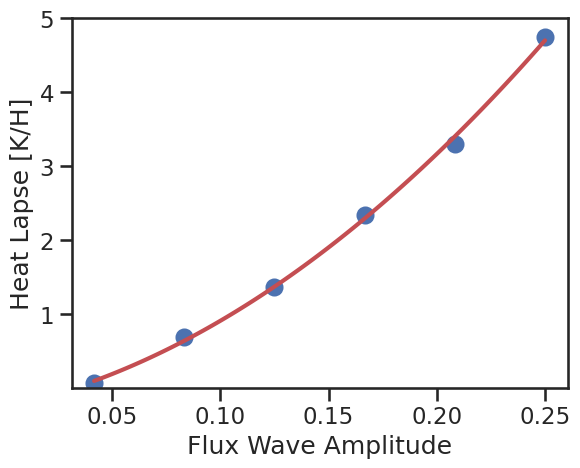

In [27]:
df_grouped = unique_heat_lapses[unique_heat_lapses['Cell Size'] == 6].groupby('Amp').agg({'Heat Lapse': 'max', 'Cum Length':'max'}).reset_index()
ax = df_grouped.plot.scatter(x='Amp', y='Heat Lapse', s=100, lw=3)
ax.set_xlabel('Flux Wave Amplitude')
ax.set_ylabel('Heat Lapse [K/H]')
ax.set_ylim(1e-5, 5.0)

# Fit a polynomial to the data
params = np.polyfit(df_grouped['Amp'], df_grouped['Heat Lapse'], 2)
x = np.linspace(df_grouped['Amp'].min(), df_grouped['Amp'].max(), 100)
y = np.polyval(params, x)
plt.plot(x, y, lw=3, color='r')

df_grouped

In [ ]:
# paths_and_patterns = [
#     ('/mnt/i/ArchiveSims/Results_20240709_173728/', 'growth_peak_data_3[0-5]azi_*.pkl'),
#     ('/mnt/i/ArchiveSims/Results_20240710_052918/', 'growth_peak_data_3[0-5]azi_*.pkl'),
#     ('/mnt/i/ArchiveSims/Results_20240710_055238.001/', 'growth_peak_data_3[0-5]azi_*.pkl'),
#     ('/mnt/i/ArchiveSims/Results_20240710_060431.857/', 'growth_peak_data_3[0-5]azi_*.pkl'),
#     ('/mnt/i/ArchiveSims/Results_20240710_062313.290/', 'growth_peak_data_3[0-5]azi_*.pkl'),
#     ('/mnt/i/ArchiveSims/Results_20240710_063136.827/', 'growth_peak_data_3[0-5]azi_*.pkl'),
#     ('/mnt/i/ArchiveSims/Results_20240708_190025/', 'growth_peak_data_3[0-5]azi_*.pkl'),
#     ('/mnt/i/ArchiveSims/Results_20240703_204726/', 'growth_peak_data_3[0-5]azi_*.pkl'),
#     ('/mnt/i/ArchiveSims/Results_20240708_230150/', 'growth_peak_data_3[0-5]azi_*.pkl'),
# ]

# pickle_data_dicts = []
# pickle_basenames_list = []

# for dir_path, pattern in paths_and_patterns:
#     pickle_data_dict, pickle_basenames = extract_pickle_data(dir_path, pattern)
#     pickle_data_dicts.append(pickle_data_dict)
#     pickle_basenames_list.append(pickle_basenames)

Found 6 pickle files
Found 6 pickle files
Found 6 pickle files
Found 6 pickle files
Found 6 pickle files
Found 6 pickle files
Found 3 pickle files
Found 1 pickle files
Found 4 pickle files


In [ ]:
# sorted_keys_list = []
# for pickle_data_dict in pickle_data_dicts:
#     sorted_keys = sorted(pickle_data_dict.keys(), key=lambda x: int(x.split('_')[5][:-3]))
#     sorted_keys_list.append(sorted_keys)

In [ ]:
# from itertools import cycle

# def compare_growth_plots(datasets_of_pickles, sorted_keys, datasets_labels=None, subsets_labels=None):
#     # datasets_of_pickles: list of dictionaries, where each dictionary is a set of pickled datasets
#     # sorted keys: list of sorted keys to use on every element of datasets_of_pickles

#     # Create a grid of subplots
#     num_plots = len(datasets_of_pickles[0]) # or equally len(sorted_keys[i])
#     num_datasets = len(datasets_of_pickles)
#     assert all(len(dp) == num_plots for dp in datasets_of_pickles), 'The number of files in the datasets are not the same'
#     num_cols = 3  # Number of columns in the grid
#     num_rows = (num_plots + num_cols - 1) // num_cols  # Number of rows in the grid

#     print(num_rows, num_cols, num_plots)

#     fig, axes = plt.subplots(num_rows, num_cols, figsize=(14, 8), sharex=True, sharey=True, squeeze=False)
#     colors = sns.color_palette('tab10', num_datasets)

#     if datasets_labels is None:
#         datasets_labels = [f'Dataset {i}' for i in range(num_datasets)]

#     if subsets_labels is None:
#         subsets_labels = [f'Subset {i}' for i in range(num_plots)]

#     for i, (set_of_pickles, label, sorted_keys) in enumerate(zip(datasets_of_pickles, datasets_labels, sorted_keys)):
#         color = colors[i]
#         for key, ax in zip(sorted_keys, axes.flat):
#             data = set_of_pickles[key]
#             ax.plot(data['peaks'][:, -1], data['radial_distance'], label=label, color=color)

#     # enable legend
#     axes.flat[0].legend(fontsize='xx-small')

#     # set titles according to .split('_')[3] (e.g., ##azi)
#     for i, (title, ax) in enumerate(zip(subsets_labels, axes.flat)):
#         ax.set_title(title)
#         ax.plot(tian_grow, tian_altitudes, label = 'Tian et al., 2023', lw=1, color='k', ls='--')

#     # Remove the empty subplots
#     for ax in axes.flat[num_plots:]:
#         ax.remove()

#     # set y labels of the first column
#     for ax in axes[:, 0]:
#         ax.set_ylabel('Radial Distance (km)')

#     # set x labels of the last row
#     for ax in axes[-1, :]:
#         ax.set_xlabel('Density amplitude growth')

#     plt.tight_layout()

# # assert len(pickle_data_dict_052918) == len(pickle_data_dict_173728), 'The number of files in the two datasets are not the same'
# # colors = sns.color_palette('tab10', len(pickle_data_dict_052918))


# compare_growth_plots(pickle_data_dicts, sorted_keys_list,
#                      datasets_labels=['Amp=0.0417', 'Amp=0.083', 'Amp=0.125', 'Amp=0.167', 'Amp=0.20', 'Amp=0.25'][::-1], 
#                      subsets_labels=[k.split('_')[5] for k in sorted_keys_list[0]])


In [ ]:
# # datasets_of_pickles = [pickle_data_dict_052918, pickle_data_dict_173728]
# # sorted_keys_list = [sorted_keys_052918, sorted_keys_173728]
# # pickle_data_dicts, sorted_keys_list


# assert all(len(skeys) == len(sorted_keys_list[0]) for skeys in sorted_keys_list[1:]), 'The number of files in the datasets are not the same'
# datasets_labels=['Amp=0.0417', 'Amp=0.083', 'Amp=0.125', 'Amp=0.167', 'Amp=0.20', 'Amp=0.25'][::-1]

# # check unique azi## values in first key
# azi_values = [key.split('_')[5] for key in sorted_keys_list[0]]

# # for each azi## value, get a dictionary with the data from each dataset with the corresponding azi## value
# flipped_list_of_dicts = []
# flipped_list_of_keys = []
# for azi in azi_values:
#     azi_dict = {}
#     for dataset, sorted_keys in zip(pickle_data_dicts, sorted_keys_list):
#         for key in sorted_keys:
#             if key.split('_')[5] == azi:
#                 azi_dict[key] = dataset[key]
#     flipped_list_of_dicts.append(azi_dict)

# flipped_sorted_keys = [list(azi_dict.keys()) for azi_dict in flipped_list_of_dicts]

In [ ]:
# compare_growth_plots(flipped_list_of_dicts, flipped_sorted_keys, datasets_labels=azi_values, subsets_labels=datasets_labels)

In [ ]:
import pandas as pd

# Initialize an empty list to collect data
collected_data = []
datasets_labels=['Amp=0.25', 'Amp=0.25', 'Amp=0.25', 'Amp=0.0417', 'Amp=0.083', 'Amp=0.125', 'Amp=0.167', 'Amp=0.20', 'Amp=0.25'][::-1]

# Iterate over each dataset and its label
for dataset, label, sorted_keys in zip(pickle_data_dicts, datasets_labels, sorted_keys_list):
    for key in sorted_keys:
        # Assuming each dataset is a dictionary where the key leads to the needed data
        data = dataset[key]
        
        # Extract subset label from the key
        subset_label = key.split('_')[5]
        
        # Assuming data['radial_distance'] is the data we're interested in
        # for radial_distance in data['radial_distance']:
        for growth, radial_distance in zip(data['peaks'][:, -1], data['radial_distance']):
            # Store each piece of data as a dictionary
            data_point = {
                'Amp': label.strip('Amp='),
                'Azi': subset_label,
                'Radial Distance': radial_distance,
                'Density Amplitude Growth': growth,
                'Density Amplitude': growth * data['baseline_peak_amps'][-1],
                'Cell Size': len(data['azi_osci']),
                'Heat Lapse': data['heat_slope_H'],
            }
            collected_data.append(data_point)

# Convert the list of dictionaries into a DataFrame
df = pd.DataFrame(collected_data)

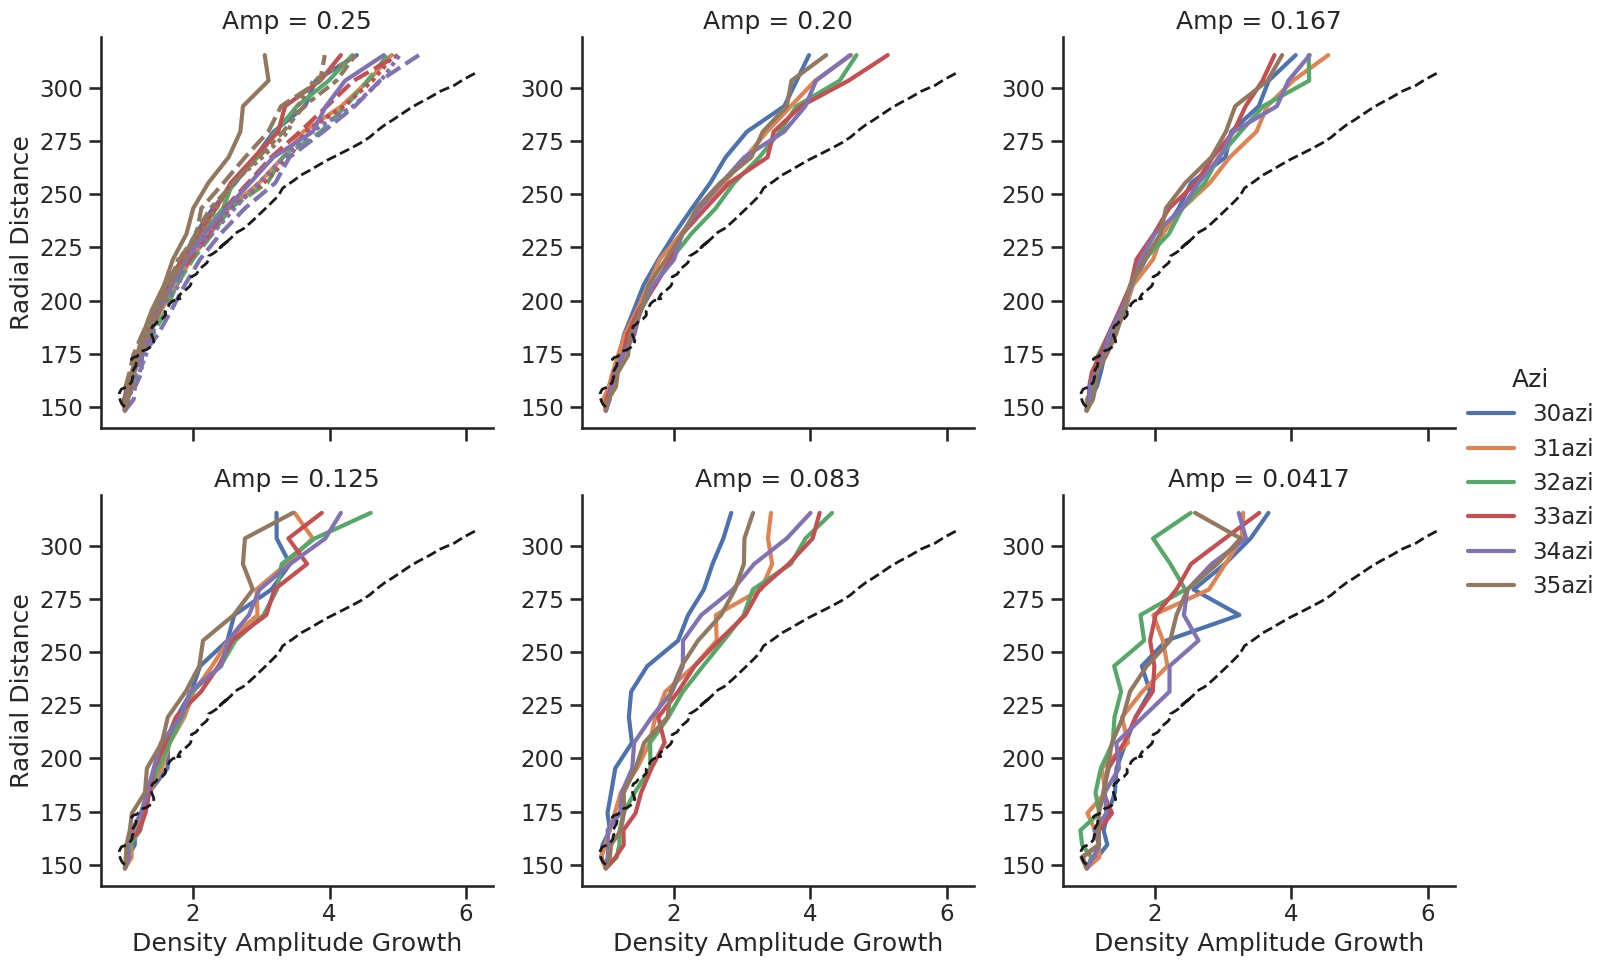

In [ ]:
# now use sns.FacetGrid to plot the data
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)
    g = sns.FacetGrid(df, col='Amp', hue='Azi', sharey=False, height=5, col_wrap=3)
    g.map_dataframe(sns.lineplot, 'Density Amplitude Growth', 'Radial Distance', orient='y', lw=3, style='Cell Size', dashes=True, estimator=None)
    # line plot tian_grow as well for every subplot
    for ax in g.axes.flat:
        ax.plot(tian_grow, tian_altitudes, label = 'Tian et al., 2023', lw=2, color='k', ls='--')
g.add_legend()

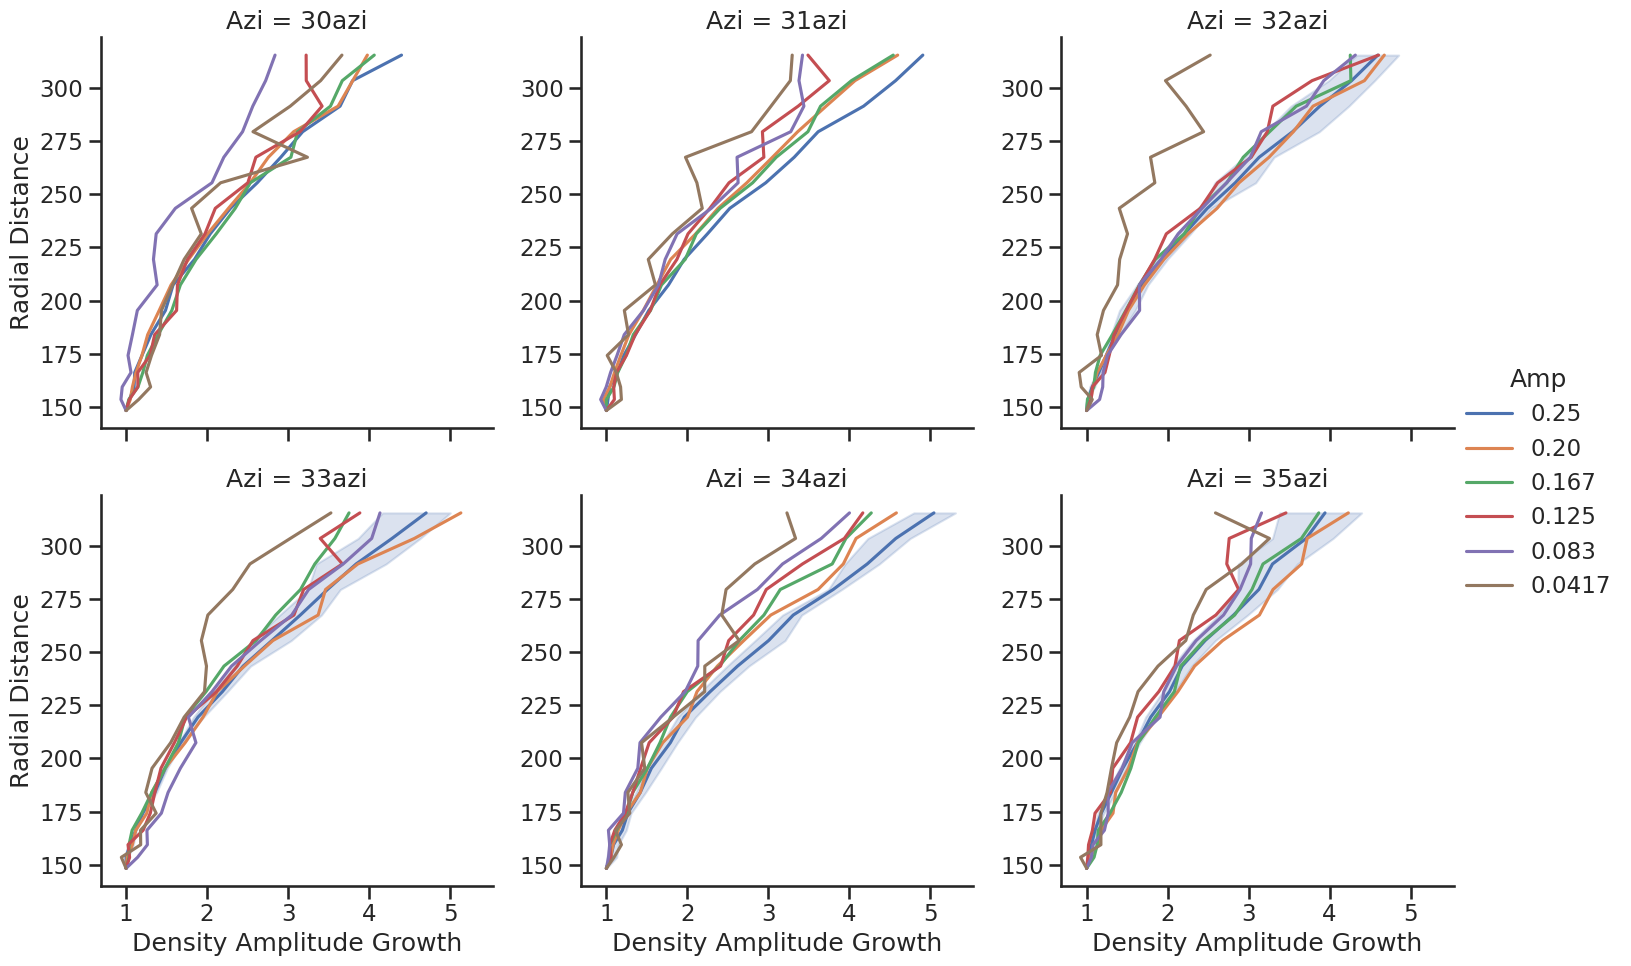

In [ ]:
# now use sns.FacetGrid to plot the data
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)
    g = sns.FacetGrid(df, col='Azi', hue='Amp', sharey=False, height=5, col_wrap=3)
    g.map(sns.lineplot, 'Density Amplitude Growth', 'Radial Distance', orient='y')
g.add_legend()

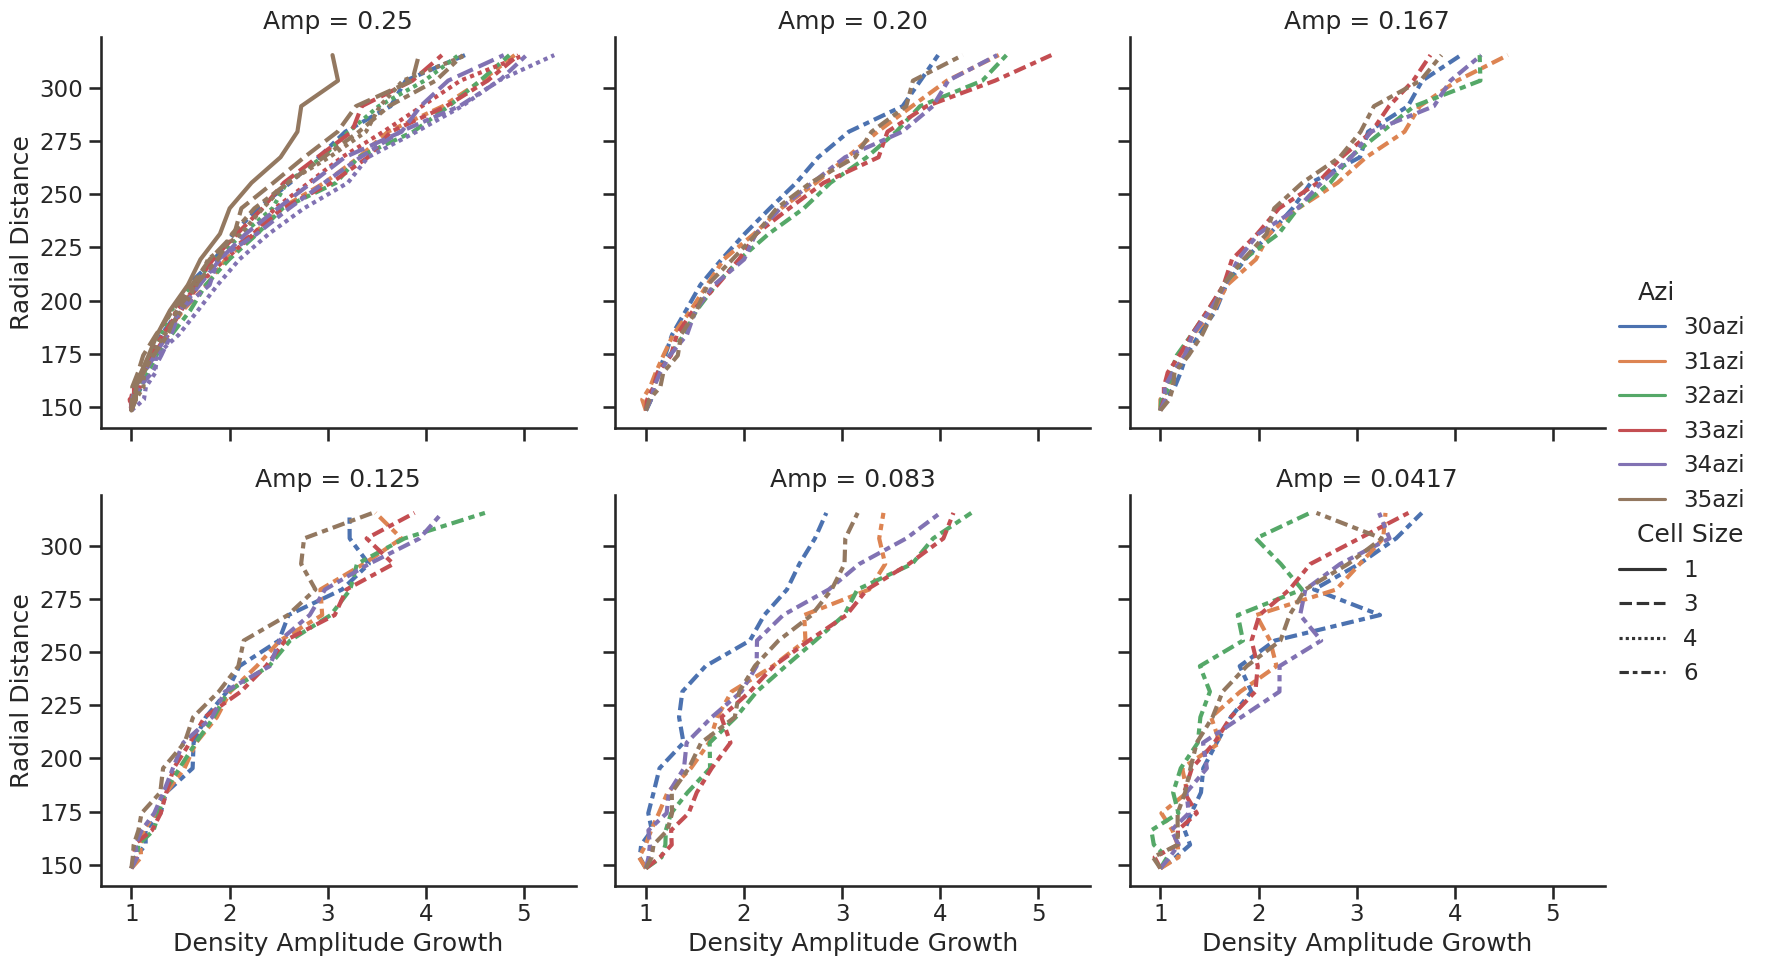

In [ ]:
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)

    g = sns.relplot(
        data=df, x='Density Amplitude Growth', y='Radial Distance', col='Amp', col_wrap=3,
        hue='Azi', style='Cell Size', kind='line', height=5, aspect=1.1, lw=3, orient='y', estimator=None,
    )

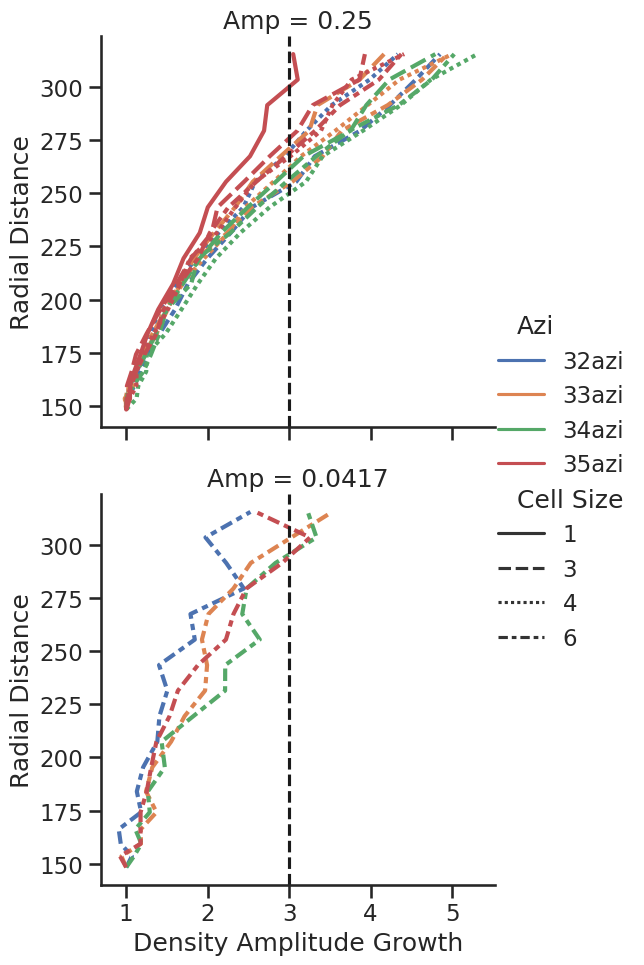

In [ ]:
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)

    # filter out Amp != 0.25 AND only show Azi == 33-35azi
    df_025 = df[(df['Amp'].isin(['0.25', '0.0417'])) & (df['Azi'].isin(['32azi', '33azi', '34azi', '35azi']))]

    g = sns.relplot(
        data=df_025, x='Density Amplitude Growth', y='Radial Distance', hue='Azi', style='Cell Size', row='Amp',
        kind='line', height=5, aspect=1.1, lw=3, orient='y', estimator=None,
    )

    # draw a vertical line at x=3 for all rows
    for ax in g.axes.flat:
        ax.axvline(3, ls='--', color='k')

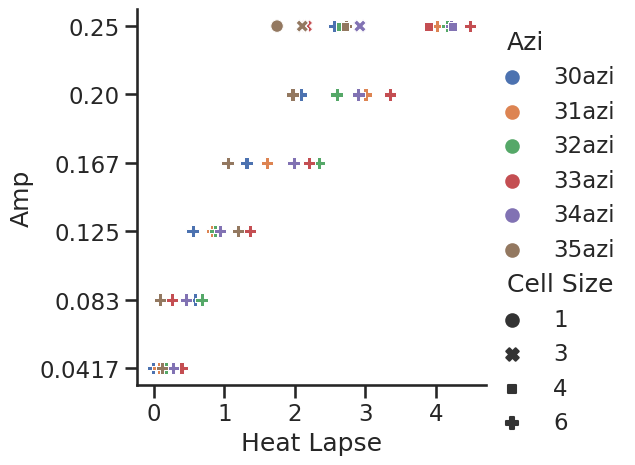

In [ ]:
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)

    # filter out Amp != 0.25 AND only show Azi == 33-35azi
    # df_025 = df[(df['Amp'].isin(['0.25', '0.0417'])) & (df['Azi'].isin(['32azi', '33azi', '34azi', '35azi']))]

    g = sns.relplot(
        data=df, x='Heat Lapse', y='Amp', hue='Azi', style='Cell Size',
        height=5, aspect=1.1, lw=3,
    )


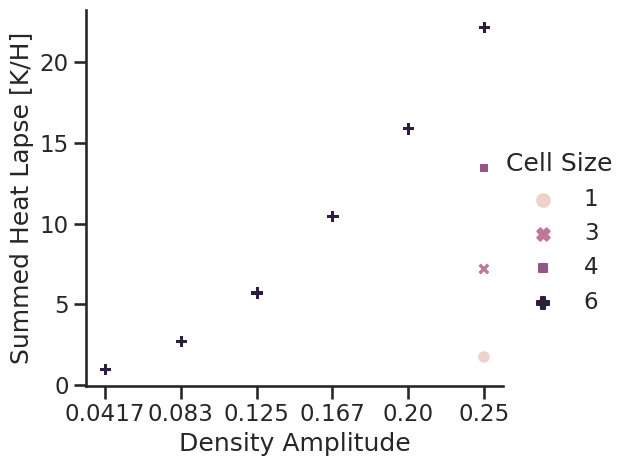

In [ ]:
unique_heat_lapses = df[['Heat Lapse', 'Amp', 'Azi', 'Cell Size']].drop_duplicates()

# now groupby Cell Size and Azi and plot the summed Heat Lapse as a function of Amp
df_grouped = unique_heat_lapses.groupby(['Cell Size', 'Amp']).agg({'Heat Lapse': 'sum'}).reset_index()

# sort by Amp
df_grouped = df_grouped.sort_values('Amp')

import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)
    g = sns.relplot(
        data=df_grouped, x='Amp', y='Heat Lapse', hue='Cell Size', style='Cell Size',
        height=5, aspect=1.1, lw=3,
    )
    g.set_ylabels('Summed Heat Lapse [K/H]')
    g.set_xlabels('Density Amplitude')